# 04 回流预测与触达时机

**业务问题**：哪些沉默用户会自然回流？应该在用户沉默第几天触达？

**核心结论**

- **沉默时长和历史行为强度各自独立地预测回流**：「早期风险 × 高强度」用户 7 天自然回流率 32%，同层其余用户只有 14.5%。召回优先级据此排序。
- 高强度用户沉默 6 天后，自然回流的概率趋于平稳。**建议在沉默第 6–8 天触达**：既避免把成本花在本来就会回来的用户身上，又能在流失加深之前介入。
- 触达时机基于自然行为推断，需要用实验验证（见报告 05）。

本节只使用「是否来访」，不涉及购买数据，不受 11 月中旬购买数据缺失的影响。

In [1]:
from nbutils import *
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint

## 1. 回流预测：滚动快照验证

只在窗口末尾分一次层，会用到「事后才知道」的信息。这里改成**滚动评估**：选一批评估日，每个评估日只用截至当天的数据计算 recency、
分层和历史强度，再看之后 7 天有没有回来。每个「评估日 × 用户」是一条样本。

评估日取 **10-31 ~ 11-07**：
- 不早于 10-31，保证有 30 天历史，「沉默 15–30 天」能完整观察到；
- 不晚于 11-07，保证 7 天观察期在大促（11-15）之前结束，回流不被大促抬高。

实现上用 `dws_user_visit_interval`：每个用户的每个活跃日带着「下一次活跃日」和截至当天的累计事件数，
评估日落在哪个区间，就取那一行——不需要对 1 亿条事件反复扫描。

In [2]:
PANEL_SQL = """
    WITH ev AS (
        SELECT CAST(generate_series AS DATE) AS eval_date
        FROM generate_series(DATE '{start}', DATE '{end}', INTERVAL 1 DAY)
    ),
    st AS (
        SELECT e.eval_date, v.user_id,
               e.eval_date - v.event_date      AS recency,
               e.eval_date - v.first_seen_date AS tenure,
               v.cum_events, v.cum_active_days,
               CASE WHEN v.next_active_date - e.eval_date <= 7 THEN 1 ELSE 0 END AS return_7d
        FROM ev e JOIN dws_user_visit_interval v
          ON v.event_date <= e.eval_date
         AND (v.next_active_date IS NULL OR v.next_active_date > e.eval_date)
    ),
    s AS (SELECT *, lifecycle_stage(tenure, recency) AS stage FROM st)
    SELECT *,
           PERCENT_RANK() OVER (PARTITION BY eval_date, stage ORDER BY cum_events DESC) < 0.3 AS top30
    FROM s
    WHERE stage IN ('early_risk', 'accelerating', 'long_lapsed')
"""

def summarize(start, end):
    g = q(f"""SELECT stage, top30, COUNT(*) AS n, SUM(return_7d) AS k
              FROM ({PANEL_SQL.format(start=start, end=end)}) GROUP BY 1, 2""")
    g["return_7d"] = g.k / g.n
    lo, hi = proportion_confint(g.k, g.n, method="wilson")
    g["ci95"] = [f"[{a:.1%}, {b:.1%}]" for a, b in zip(lo, hi)]
    return g.sort_values(["stage", "top30"], key=lambda s: s.map(stage_rank) if s.name == "stage" else ~s)

stage_rank = {s: i for i, s in enumerate(STAGES)}
main = summarize("2019-10-31", "2019-11-07")
main.assign(stage=main.stage.map(STAGE_CN), top30=main.top30.map({True: "前30%", False: "后70%"})) \
    [["stage", "top30", "n", "return_7d", "ci95"]] \
    .rename(columns={"stage": "评估日所处分层", "top30": "层内历史强度", "n": "样本数（评估日×用户）",
                     "return_7d": "7 天内自然回来", "ci95": "95% 置信区间"}) \
    .style.format({"样本数（评估日×用户）": "{:,}", "7 天内自然回来": "{:.1%}"}).hide(axis="index")

评估日所处分层,层内历史强度,样本数（评估日×用户）,7 天内自然回来,95% 置信区间
早期风险,前30%,"1,741,552",32.3%,"[32.2%, 32.3%]"
早期风险,后70%,"3,892,772",14.5%,"[14.4%, 14.5%]"
加速流失,前30%,"2,998,180",19.3%,"[19.3%, 19.4%]"
加速流失,后70%,"6,371,624",10.7%,"[10.6%, 10.7%]"
长期沉默,前30%,"511,233",10.9%,"[10.8%, 11.0%]"
长期沉默,后70%,"1,019,907",7.5%,"[7.4%, 7.5%]"


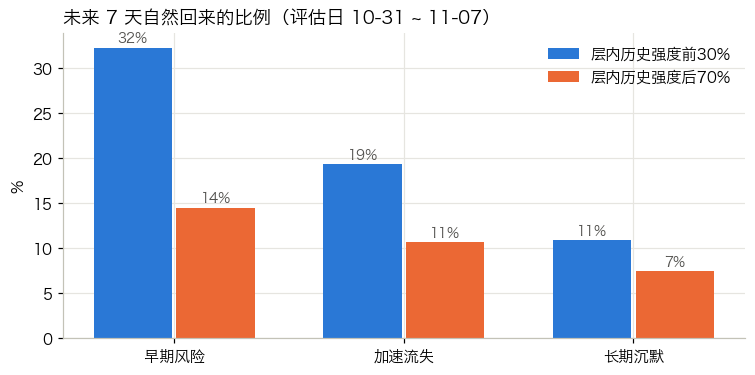

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(3)
for j, (t, name, c) in enumerate([(True, "层内历史强度前30%", PALETTE[0]), (False, "层内历史强度后70%", PALETTE[1])]):
    v = main[main.top30 == t].set_index("stage").loc[["early_risk", "accelerating", "long_lapsed"], "return_7d"]
    ax.bar(x + (j - 0.5) * 0.36, v * 100, width=0.34, color=c, label=name)
    for xi, val in zip(x, v):
        ax.text(xi + (j - 0.5) * 0.36, val * 100 + 0.6, f"{val:.0%}", ha="center", fontsize=9, color="#52514e")
ax.set_xticks(x, [STAGE_CN[s] for s in ["early_risk", "accelerating", "long_lapsed"]])
ax.set(ylabel="%", title="未来 7 天自然回来的比例（评估日 10-31 ~ 11-07）")
ax.legend()
plt.show()

- **强度能预测回流**：同一层里，前 30% 的人 7 天内自然回来的比例是后 70% 的 1.5–2.2 倍；
- **沉默时长能预测回流**：同样是前 30%，早期风险层 32% 会回来，加速流失层只有 19%；
- 样本量是百万级，置信区间窄到可以忽略，差异不是噪声。

所以召回的优先级是：**早期风险 × 前30% → 加速流失 × 前30% → 早期风险 × 后70% → 其余**。
排在前面的人群自然回流率高，说明使用惯性仍在，被触达后回流的可能性也更大（需实验验证，见报告 05）。

### 稳健性：换到大促之后的评估日

换一批评估日（11-18 ~ 11-23，观察期在大促之后），看排序会不会变。

In [4]:
post = summarize("2019-11-18", "2019-11-23")
cmp = main.set_index(["stage", "top30"]).return_7d.rename("10-31~11-07").to_frame() \
    .join(post.set_index(["stage", "top30"]).return_7d.rename("11-18~11-23"))
cmp.index = [f"{STAGE_CN[s]} × {'前30%' if t else '后70%'}" for s, t in cmp.index]
cmp.style.format("{:.1%}")

,10-31~11-07,11-18~11-23
早期风险 × 前30%,32.3%,23.4%
早期风险 × 后70%,14.5%,10.5%
加速流失 × 前30%,19.3%,14.7%
加速流失 × 后70%,10.7%,7.0%
长期沉默 × 前30%,10.9%,7.1%
长期沉默 × 后70%,7.5%,4.5%


大促后整体回流率不同，但「早期风险 > 加速流失 > 长期沉默」「前 30% > 后 70%」的排序完全不变。

### 两个因素是否各自独立起作用

早期风险层的人历史强度本来就更高，「沉默越久越不回来」会不会只是强度差异的影子？
用逻辑回归把两者放在一起，同时控制活跃天数和在窗口里待了多久：

In [5]:
sample = q(f"SELECT * FROM ({PANEL_SQL.format(start='2019-10-31', end='2019-11-07')}) USING SAMPLE 300000 ROWS (reservoir, 42)")
X = pd.DataFrame({
    "沉默天数": sample.recency,
    "log(历史事件数)": np.log(sample.cum_events),
    "log(历史活跃天数)": np.log(sample.cum_active_days),
    "在窗口内的天数": sample.tenure,
})
model = sm.Logit(sample.return_7d, sm.add_constant(X)).fit(disp=False)
coef = pd.DataFrame({"系数": model.params, "优势比": np.exp(model.params),
                     "95% 下限": np.exp(model.conf_int()[0]), "95% 上限": np.exp(model.conf_int()[1]),
                     "p 值": model.pvalues}).drop("const")
coef.style.format({"系数": "{:+.3f}", "优势比": "{:.3f}", "95% 下限": "{:.3f}", "95% 上限": "{:.3f}", "p 值": "{:.1e}"})

,系数,优势比,95% 下限,95% 上限,p 值
沉默天数,-0.056,0.945,0.943,0.948,0.0e+00
log(历史事件数),+0.234,1.264,1.250,1.279,0.0e+00
log(历史活跃天数),+0.140,1.151,1.112,1.190,4.5e-16
在窗口内的天数,+0.034,1.034,1.031,1.037,6.3e-145


In [6]:
auc = pd.Series({
    "只用沉默天数": roc_auc_score(sample.return_7d, -sample.recency),
    "只用历史事件数": roc_auc_score(sample.return_7d, sample.cum_events),
    "逻辑回归（四个变量）": roc_auc_score(sample.return_7d, model.predict(sm.add_constant(X))),
}, name="AUC")
auc.to_frame().style.format("{:.3f}")

,AUC
只用沉默天数,0.594
只用历史事件数,0.644
逻辑回归（四个变量）,0.664


- 控制强度后，**每多沉默一天，7 天内回流的优势比（odds ratio）下降约 5%**；控制住沉默天数之后，历史强度和活跃天数都显著为正。
  两个因素各自独立起作用；
- 两个因素合起来 AUC 约 0.66（AUC 衡量模型区分「会回流」和「不会回流」的能力，0.5 相当于随机，1 为完美），优于单独使用任一因素，但还不足以精准预测个人。
  因此召回名单应**按人群分组确定优先级**，而不是依赖模型为每个人打分。
  要把 AUC 做上去，需要这份数据里没有的信号：最近一次访问看了什么、购物车里还有没有东西、有没有收到过推送。

## 2. 触达时机：回访风险函数

换一个角度问：用户每多沉默一天，**第二天回来的概率**是多少？这就是离散时间的风险函数（hazard）：

$$h(k) = P(\text{在第 } k \text{ 天回来} \mid \text{前 } k-1 \text{ 天都没回来})$$

分母只算「到第 k 天还在观察期内、而且还没回来」的人。观察期截到 11-14（避开大促），没等到下一次访问的样本按删失处理——
如果直接用「两次访问间隔」的分布代替风险函数，观察期不足的样本会被误判为「未回流」，导致回流被系统性低估。

样本：10 月里每一次「某用户在某天来访」，看他下一次什么时候来。按该次来访时的累计强度在当天所有来访者中分前 30% / 后 70%。

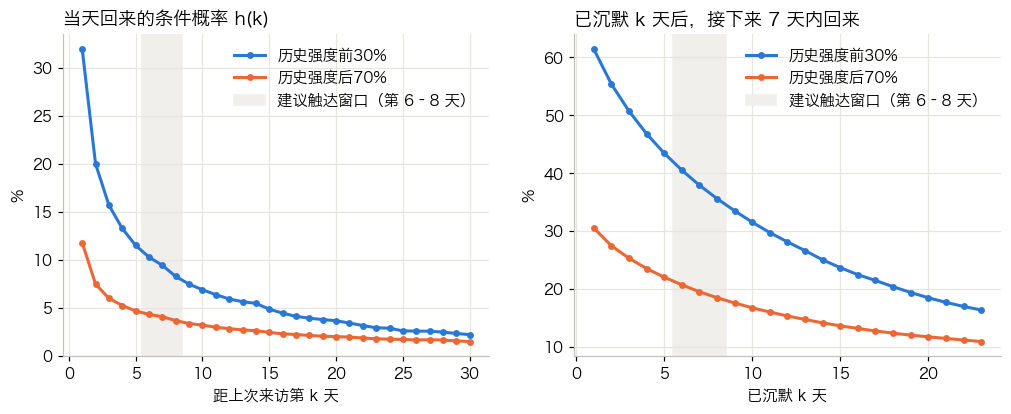

h(k) 每多等一天下降不到 1 个百分点的起点：前30% 第 6 天，后70% 第 3 天


,h(k) · 后70%,h(k) · 前30%,之后7天内回来 · 后70%,之后7天内回来 · 前30%
k,,,,
1,11.8%,32.0%,30.6%,61.4%
2,7.5%,20.0%,27.5%,55.4%
3,6.0%,15.7%,25.3%,50.7%
5,4.7%,11.5%,22.1%,43.5%
7,4.1%,9.4%,19.6%,37.9%
8,3.7%,8.3%,18.5%,35.6%
10,3.2%,6.9%,16.8%,31.6%
14,2.6%,5.5%,14.2%,25.1%


In [7]:
hz = q("""
    WITH v AS (
        SELECT event_date, cum_events,
               CASE WHEN next_active_date <= DATE '2019-11-14' THEN next_active_date - event_date END AS gap,
               DATE '2019-11-14' - event_date AS follow_up
        FROM dws_user_visit_interval
        WHERE event_date BETWEEN '2019-10-01' AND '2019-10-31'
    ),
    v2 AS (SELECT *, PERCENT_RANK() OVER (PARTITION BY event_date ORDER BY cum_events DESC) < 0.3 AS top30 FROM v),
    k AS (SELECT CAST(range AS INTEGER) AS k FROM range(1, 31))
    SELECT top30, k,
           COUNT(*) FILTER (WHERE COALESCE(gap, 9999) >= k AND follow_up >= k) AS at_risk,
           COUNT(*) FILTER (WHERE gap = k) AS returned
    FROM v2, k GROUP BY 1, 2 ORDER BY 1, 2
""")
hz["hazard"] = hz.returned / hz.at_risk
hz["survival"] = hz.groupby("top30").hazard.transform(lambda h: (1 - h).cumprod())
hz["next7"] = hz.groupby("top30").survival.transform(lambda s: 1 - s.shift(-7) / s)   # 已沉默 k 天，之后 7 天内回来
hz["drop"] = hz.groupby("top30").hazard.diff(-1)                                       # 再多等一天，h 下降多少

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for t, name, c in [(True, "历史强度前30%", PALETTE[0]), (False, "历史强度后70%", PALETTE[1])]:
    g = hz[hz.top30 == t]
    axes[0].plot(g.k, g.hazard * 100, color=c, marker="o", markersize=3.5, label=name)
    g7 = g.dropna(subset=["next7"])
    axes[1].plot(g7.k, g7.next7 * 100, color=c, marker="o", markersize=3.5, label=name)
axes[0].set(xlabel="距上次来访第 k 天", ylabel="%", title="当天回来的条件概率 h(k)")
axes[1].set(xlabel="已沉默 k 天", ylabel="%", title="已沉默 k 天后，接下来 7 天内回来")
for ax in axes:
    ax.axvspan(5.5, 8.5, color=SHADE, zorder=0, label="建议触达窗口（第 6–8 天）")
    ax.legend()
plt.show()

elbow = {}
for t in (True, False):
    g = hz[hz.top30 == t].set_index("k")
    elbow[t] = int(g[g["drop"] < 0.01].index.min())
tbl = hz[hz.k.isin([1, 2, 3, 5, 7, 8, 10, 14])].pivot(index="k", columns="top30", values=["hazard", "next7"])
tbl.columns = [f"{'h(k)' if a == 'hazard' else '之后7天内回来'} · {'前30%' if b else '后70%'}" for a, b in tbl.columns]
print(f"h(k) 每多等一天下降不到 1 个百分点的起点：前30% 第 {elbow[True]} 天，后70% 第 {elbow[False]} 天")
tbl.style.format("{:.1%}")

**风险函数单调下降，不存在某个回流概率骤降的单一日期**，但下降速度有明显拐点：

- 高强度用户沉默的头几天，回流概率下降很快（第 1 天 32% → 第 3 天 16%）；从第 6 天起，每多等一天只再降不到 1 个百分点；
- 也就是说：**前 5 天触达，成本会有相当一部分落在本来就会自然回流的用户身上；第 6 天以后，自然回流概率已接近底部，继续等待节省有限，而用户的使用惯性在持续减弱**；
- 低强度用户的拐点更早（第 3 天左右），但这部分用户回流率基数低、价值也低，适合用低成本渠道批量触达。

**建议的触达时机：高强度用户沉默第 6–8 天**（图中灰色带），也就是正要从「健康」滑进「早期风险」的那几天。
此时「之后 7 天内自然回流」的概率已从沉默 1 天时的 61% 降至 36%–41%，而用户尚未进入深度流失。

这是基于自然行为的推断，「什么时候触达效果最好」本身需要实验回答——报告 05 的实验方案里把触达时机也设计成了一个实验维度。